# Level 2 — FinBERT

Daily next-fixing USD/IDR UP/DOWN on the combined corpus. See [the protocol](../PROTOCOL.md) for selection and test scope.

In [1]:
from pathlib import Path
import os
import sys
import json

for key in ["OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[key] = "1"
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import torch
from threadpoolctl import threadpool_limits
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/final/metadata.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.task_3.training.experiment import Experiment, prepare_run, freeze_final, final_report, read_json, OUTPUT, FIGURES

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
threadpool_limits(limits=1)
pd.options.display.float_format = "{:.4f}".format
from src.task_3.training.all_tests import prepare as prepare_all_tests, TEST_FIGURES
prepare_all_tests()
prepare_run()
experiment = Experiment(2, "R3")


## Data

Use the fixed CSV folds; purge boundaries by target availability.

In [2]:
rows = []
for fold in [1, 2, 3]:
    train, val, _, _ = experiment.frames(fold)
    for role, frame in [("train", train), ("validation", val)]:
        rows.append({"fold": fold, "role": role, "n": len(frame), "first": frame.Date.min().date(), "last": frame.Date.max().date(), "up": int(frame.y.sum()), "news": int(frame.n_berita.sum())})
display(pd.DataFrame(rows))
print("Representation:", experiment.rep)
print("Configuration:", experiment.config)


Representation: R3
Configuration: {'family': 'small_mlp', 'view': 'text', 'centered': False, 'alpha': 0.01, 'dropout': 0.2}


,fold,role,n,first,last,up,news
0,1,train,453,2021-09-29,2023-08-15,260,6759
1,1,validation,158,2023-08-21,2024-04-19,94,2105
2,2,train,612,2021-09-29,2024-04-19,355,8886
3,2,validation,159,2024-04-23,2024-12-12,81,1960
4,3,train,772,2021-09-29,2024-12-12,437,10865
5,3,validation,158,2024-12-16,2025-08-26,79,1945


## Training

Select checkpoints by five-epoch mean validation log loss. Report individual-seed averages; logistic regression is a benchmark for fixed concat inputs.

In [3]:
summary = experiment.train()
display(summary)
for filename in ["logistic_comparison.csv", "diagnostics.csv"]:
    path = experiment.directory / filename
    if path.exists():
        display(pd.read_csv(path))


,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
statistic,,,,,,,,
mean,0.0089,0.3495,0.5007,0.5355,0.5007,0.2489,0.6909,0.0376
std,0.0154,0.0204,0.0012,0.0516,0.0012,0.0059,0.0118,0.0050


,C,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
0,0.0100,-0.0475,0.4453,0.4776,0.4905,0.5028,0.2860,0.7835,0.1838


,fold,mean_pair_cosine,pc1_variance_share,median_abs_mean_over_std
0,1,0.9647,0.3071,3.4751
1,2,0.9635,0.3104,3.3736
2,3,0.9633,0.2950,3.3331


## Validation

Confusion counts average seeds. Curves show seed42 with the training-prior reference.

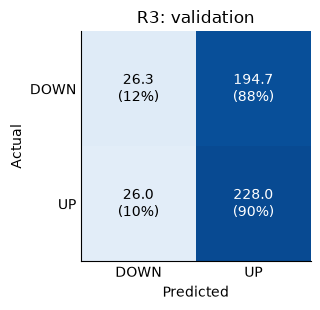

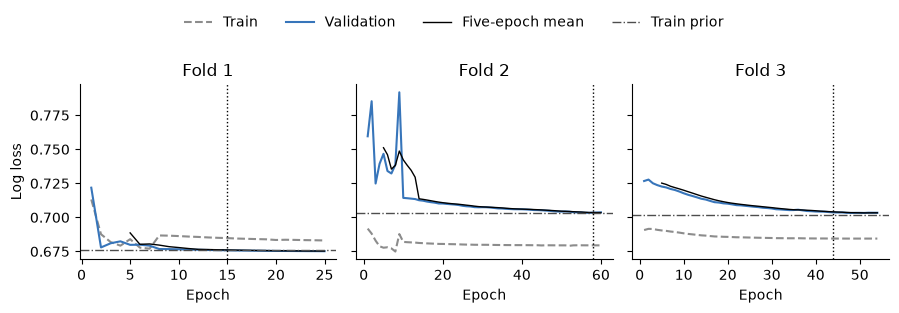

In [4]:
figures = experiment.plot()
plt.show()
for figure in figures:
    plt.close(figure)


## Saved results

Model files include training-fitted preprocessing; article encoders are shared separately.

In [5]:
display(experiment.finalize_level())
metadata = read_json(experiment.directory / "run_metadata.json")
print("Saved:", experiment.directory.relative_to(ROOT))
print("Evaluation rows:", metadata["evaluation_rows"])


Saved: src/task_3/output/model/improved_v1/level_2/03_finbert
Evaluation rows: 475


,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
model_id,,,,,,,,
R1,0.0768,0.4936,0.5300,0.5502,0.5358,0.2547,0.7054,0.1034
R2,-0.0088,0.3636,0.4987,0.5313,0.5130,0.2492,0.6917,0.0408
R3,0.0089,0.3495,0.5007,0.5355,0.5007,0.2489,0.6909,0.0376
R4,0.0121,0.3526,0.5021,0.5348,0.5002,0.2489,0.6909,0.0389
T1,0.0056,0.3634,0.5028,0.5256,0.5050,0.2490,0.6910,0.0411


## Final test

Refit this condition using its validation-selected configuration and median epochs. Test comparisons are exploratory; settings remain fixed.

R3 seed42: reused verified 44-epoch model
R3 seed123: reused verified 6-epoch model
R3 seed2026: reused verified 9-epoch model
Completed test R3: MCC0.0000, AUC0.4988
Out[6]: 
    level              model_id     mcc  ...  brier  log_loss  ece_10
0       1                  L1-a  0.0000  ... 0.2439    0.6809  0.0281
1       1                  L1-b  0.0493  ... 0.4600   15.7398  0.4605
2       1                  L1-c -0.0002  ... 0.2478    0.6890  0.0827
3       1                  L1-d  0.0000  ... 0.2457    0.6845  0.0452
4       1                  L1-e  0.0170  ... 0.2468    0.6870  0.0624
5       2                    R1 -0.0865  ... 0.2556    0.7048  0.1025
6       2                    R2 -0.0080  ... 0.2452    0.6836  0.0407
7       2                    R3  0.0000  ... 0.2457    0.6845  0.0452
8       1         price_matched -0.0002  ... 0.2478    0.6890  0.0827
9       1           price_tuned  0.0800  ... 0.2443    0.6816  0.0411
10      1  availability_matched  0.0170  ... 0.2468   

,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
statistic,,,,,,,,
mean,0.0000,0.3683,0.5000,0.5830,0.4988,0.2457,0.6845,0.0452
std,0.0000,0.0000,0.0000,0.0000,0.0021,0.0026,0.0053,0.0262


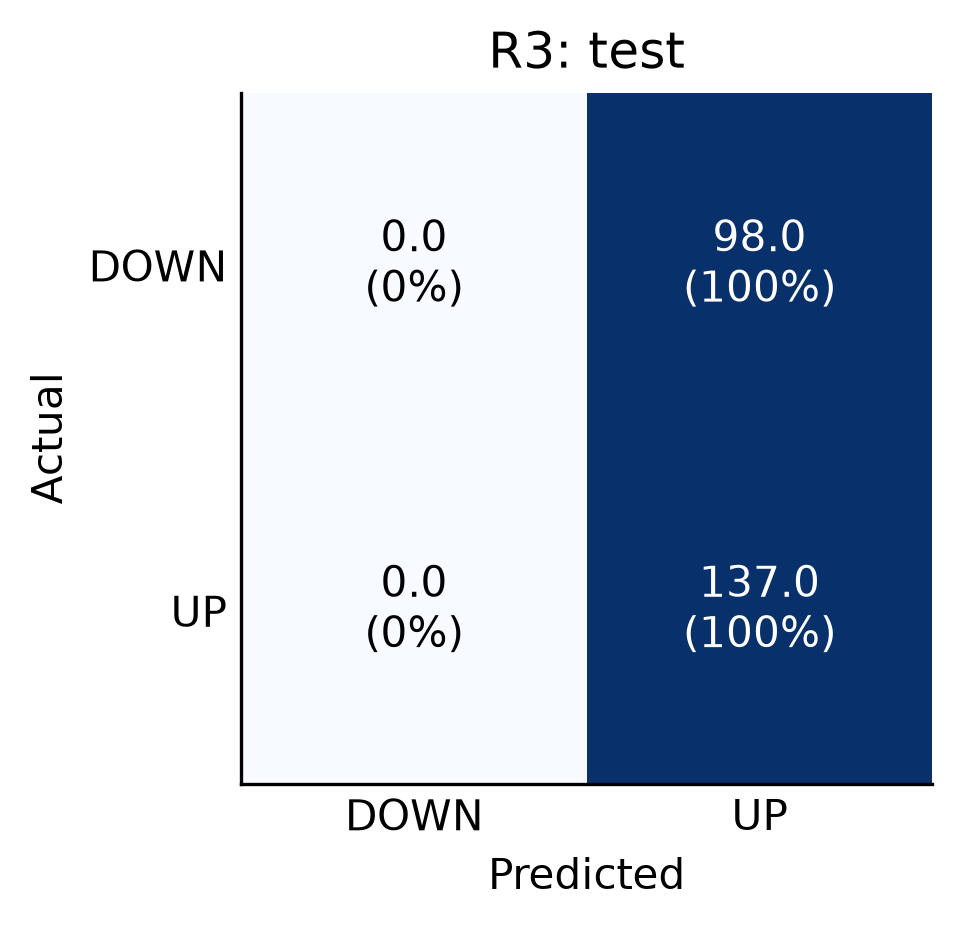

In [6]:
display(experiment.final_test())
display(Image(filename=str(TEST_FIGURES / experiment.model_id / "confusion_matrix.png")))
final_report()
